# Mouse LFP (1-20 Hz)

Examine low-frequency dynamics in a five-second mouse LFP sample. Apply a 1-20 Hz passband and envelope normalization, fit an autoregressive model, and quantify the delay embedding with an elliptical ring fit.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import neuralfieldmanifold as nfm

recording = nfm.datasets.load("mouse_lfp")
print(recording.duration_seconds, recording.sampling_rate_hz)


5.0 20000.0


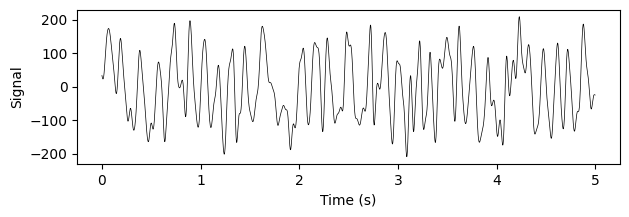

In [2]:
config = nfm.preprocessing.PreprocessConfig(
    notch_hz=50, band_hz=(1, 20), output_rate_hz=500,
    envelope_band_hz=(1, 80), envelope_lowpass_hz=3,
)
processed = nfm.preprocessing.process(
    recording.signal, sampling_rate_hz=recording.sampling_rate_hz, config=config,
)
x = processed.signal
plt.figure(figsize=(7, 2))
plt.plot(np.arange(len(x)) / processed.sampling_rate_hz, x, color="black", lw=.5)
plt.xlabel("Time (s)")
plt.ylabel("Signal")
plt.show()


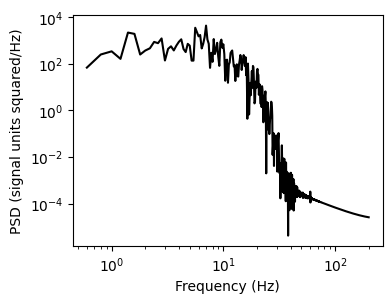

In [3]:
n_fft = min(4096, len(x))
psd = nfm.spectral.welch(x, sampling_rate_hz=500, n_fft=n_fft,
                         overlap_samples=n_fft // 2, frequency_range_hz=(.5, 200))
plt.figure(figsize=(4, 3))
plt.loglog(psd.frequencies_hz, psd.density, color="black")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (signal units squared/Hz)")
plt.show()


## Prediction

Use a temporal train/test split to evaluate the AR model on later observations. Hybrid forecasts periodically refresh the lag history with observations rather than evolving freely for the full test segment.


PredictionMetrics(mse=192.18021338711188, mae=7.938920364491352, correlation=0.989851034939013)


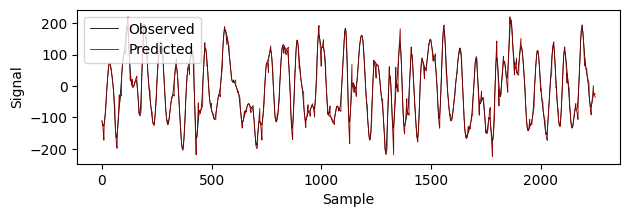

In [4]:
order = 3
n_train = int(0.1 * (len(x) - order))
fit = nfm.models.AR(order=order).fit(x[:n_train + order])
observed = x[n_train + order:]
prediction = fit.forecast(x, start_sample=n_train + order,
                          n_samples=len(observed), refresh_samples=10)
metrics = nfm.models.prediction_metrics(observed, prediction)
print(metrics)
plt.figure(figsize=(7, 2))
plt.plot(observed, color="black", label="Observed", lw=.6)
plt.plot(prediction, color="darkred", label="Predicted", lw=.6)
plt.xlabel("Sample")
plt.ylabel("Signal")
plt.legend()
plt.show()


## Delay Coordinates

Compare observed and predicted trajectories using the same delay, then fit elliptical rings. The prediction is matched to the observed mean and standard deviation for this geometric visualization, not for prediction-error calculation.


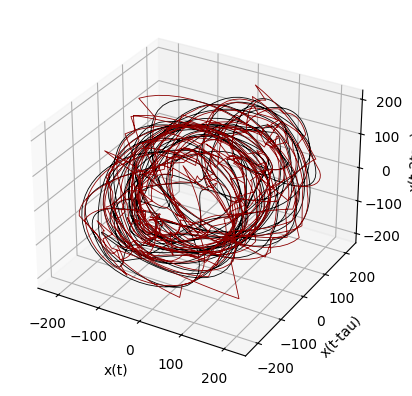

In [5]:
matched = prediction - prediction.mean()
matched = matched * (observed.std() / (matched.std() + 1e-12)) + observed.mean()
cloud = nfm.embedding.delay(observed.astype(np.float32), dimension=3, tau_samples=10)
predicted_cloud = nfm.embedding.delay(matched.astype(np.float32), dimension=3, tau_samples=10)
ax = nfm.plotting.embedding(cloud)
nfm.plotting.embedding(predicted_cloud, ax=ax, color="darkred")
plt.show()
